# Milestone 2 - Week 1: Data and Baseline Foundation
## (pre-labeled Hugging Face maze-curriculum dataset)

Rebuilt on **`selimaktas/maze-curriculum-dataset`** (Hugging Face, MIT license,
60k ASCII mazes with provided solutions). The labelling question is decided
exactly as demanded: **no BFS and no other search anywhere in the data
pipeline** - the label masks are replayed from the *provided* solution strings
by pure rule-following. Search appears only in Section 4, as an *evaluation*
tool for predictions, never to create labels.

This notebook is **self-contained** (runs in Colab or locally with no repo
files next to it): models are defined inline; the only dependencies are
`torch`, `numpy`, `matplotlib` and `datasets`.

Week-1 checklist:

- [x] **Dataset selection** - a documented existing dataset (Section 1)
- [x] **Data adapter** - ASCII mazes -> 3-channel tensors, provided solutions -> masks (Section 2)
- [x] **Dataset validation** - endpoints, legality of every provided solution, duplicates (Section 3)
- [x] **Evaluation** - strict legal-path metric instead of connectivity alone (Section 4)
- [x] **First baseline** - trained RecurrentCNN (Section 5, results Section 6)
- [x] **P1: simple CNN** - non-recurrent control (Section 7)
- [x] **Hyperparameters, numerical results, visual comparisons, limitations** (Sections 5-8)


In [6]:
# ============================ 0. Setup =========================
%matplotlib inline
import json
import sys
import time
from collections import Counter, deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# hint: 'datasets' (Hugging Face) is auto-installed here if missing
try:
    import datasets
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"],
                   check=False)
    import datasets

DEVICE = torch.device("cpu")          # Week 1 runs comfortably on CPU
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

RESULTS = Path.cwd() / "week1_results"
RESULTS.mkdir(exist_ok=True)

print("torch", torch.__version__, "| numpy", np.__version__,
      "| datasets", datasets.__version__, "| device:", DEVICE)


torch 2.14.1+cpu | numpy 2.4.6 | datasets 4.8.5 | device: cpu


## 1) Dataset selection (P0)

**Chosen dataset: `selimaktas/maze-curriculum-dataset`** (Hugging Face, MIT
license). Why this one:

- a genuinely **pre-labeled, existing** dataset - solutions are *provided*
  (move strings), so the labels are not created by our own solver;
- `60,000` mazes with a built-in curriculum: grid_size 5 (25k), 7 (20k), 9 (15k)
  navigable cells - Week 1 uses the easy 5x5 level, later weeks scale up;
- per the dataset card the mazes are generated with Wilson's algorithm, i.e.
  **perfect mazes with exactly one solution path** - labels are unambiguous;
- compact (5.4 MB, parquet) and trivially re-downloadable - reproducible.

Fields per instance:

| field | type | content |
|---|---|---|
| `prompt` | string | LLM instruction text (unused here - we work on tensors) |
| `maze` | string | ASCII maze: `#` wall, ` ` free, `S` start, `E` end |
| `solution` | string | provided solution as moves N/S/E/W |
| `grid_size` | int | navigable cells per axis; ASCII grid is `2N+1` per side |

ASCII-to-tensor geometry: one move of the solution = **2 ASCII cells**
(landing cell + the wall-gap between). The Week-1 level (grid_size 5) is an
`11 x 11` ASCII grid.

Work split: the dataset ships only `train` - we carve our own
train / val / test split with a fixed seed (Section 3).


In [7]:
# ======================= 1. Load and document the dataset =======================
CONFIG = dict(
    dataset="selimaktas/maze-curriculum-dataset (Hugging Face, MIT license)",
    week1_subset="grid_size = 5  ->  ASCII 11x11 (the easy curriculum level)",
    n_train=4000, n_val=1000, n_test=1000, seed=0,
)
print(json.dumps(CONFIG, indent=2))

raw = datasets.load_dataset("selimaktas/maze-curriculum-dataset")["train"]
print("columns:", raw.column_names, "| rows:", len(raw))
print("curriculum levels (grid_size -> count):", dict(Counter(raw["grid_size"])))

ex = raw[0]
print("\nprompt[:52]:", ex["prompt"][:52])
print("grid_size:", ex["grid_size"], "| provided solution:", repr(ex["solution"]))
print("the ASCII maze (S = start, E = end):")
print(ex["maze"])

moves = [len(raw[i]["solution"]) for i in range(4000)]
moves = np.array(moves)
print("solution length on a 4k sample: mean %.1f | max %d moves"
      % (moves.mean(), moves.max()))


{
  "dataset": "selimaktas/maze-curriculum-dataset (Hugging Face, MIT license)",
  "week1_subset": "grid_size = 5  ->  ASCII 11x11 (the easy curriculum level)",
  "n_train": 4000,
  "n_val": 1000,
  "n_test": 1000,
  "seed": 0
}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


columns: ['prompt', 'maze', 'solution', 'grid_size'] | rows: 60000
curriculum levels (grid_size -> count): {5: 25000, 7: 20000, 9: 15000}

prompt[:52]: You are a navigation agent. Given an ASCII maze, mov
grid_size: 5 | provided solution: 'SEN'
the ASCII maze (S = start, E = end):
###########
# #     # #
# # ### # #
#     #   #
##### # # #
#     # # #
# #########
#S#E    # #
# # ### # #
#     #   #
###########
solution length on a 4k sample: mean 5.7 | max 19 moves


## 2) Data adapter (P0)

Two pure functions, **no search of any kind**:

- `parse_maze` - ASCII -> wall grid + start/goal coordinates + 3-channel tensor
  `[walkable, start one-hot, goal one-hot]`;
- `replay_solution` - the **provided** move string is literally replayed from
  the start cell: every move must stay in bounds, not land on or pass through a
  wall, and the walk must end exactly at `E`. Every traversed ASCII cell
  (landing cells and wall-gap cells) is marked -> the solution mask `y`.

Label semantics: for these perfect mazes the unique S->E path *is* the mask.


adapter demo OK | x: (3, 11, 11) | path cells in y: 7 | moves: 3


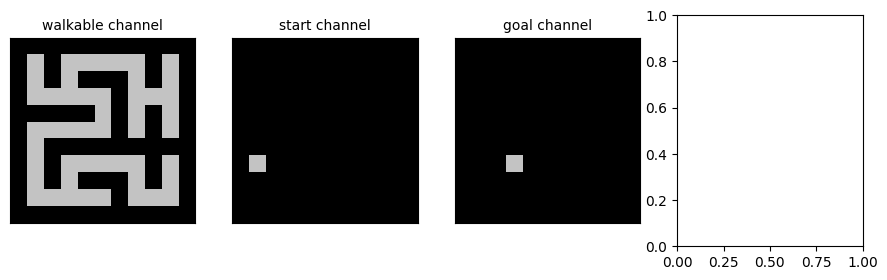

In [8]:
# ======================= 2. Adapter: ASCII -> tensors, solution -> mask =======================
DELTAS = {"N": (-2, 0), "S": (2, 0), "E": (0, 2), "W": (0, -2)}


def parse_maze(maze_str):
    # ASCII maze -> wall grid (1 = wall), start and goal coordinates
    lines = [ln for ln in maze_str.split("\n") if ln.strip()]
    H, W = len(lines), len(lines[0])
    wall = np.zeros((H, W), np.int8)
    start = goal = None
    for r, line in enumerate(lines):
        for c, ch in enumerate(line):
            if ch == "#":
                wall[r, c] = 1
            elif ch == "S":
                start = (r, c)
            elif ch == "E":
                goal = (r, c)
    return wall, start, goal


def maze_to_channels(wall, start, goal):
    # wall grid + endpoints -> model input tensor (3, H, W)
    walk = (wall == 0).astype(np.float32)
    s = np.zeros(wall.shape, np.float32); s[start] = 1.0
    g = np.zeros(wall.shape, np.float32); g[goal] = 1.0
    return np.stack([walk, s, g])


def replay_solution(wall, start, solution):
    # PROVIDED solution string -> path mask by pure rule-following (no search).
    # Marks every traversed ASCII cell (landing + gap). Returns (mask, legal).
    H, W = wall.shape
    mask = np.zeros((H, W), bool)
    mask[start] = True
    r, c = start
    for mv in solution:
        dr, dc = DELTAS[mv]
        nr, nc = r + dr, c + dc
        if not (0 <= nr < H and 0 <= nc < W):
            return mask, False
        if wall[r + dr // 2, c + dc // 2] or wall[nr, nc]:
            return mask, False
        mask[r + dr // 2, c + dc // 2] = True
        mask[nr, nc] = True
        r, c = nr, nc
    return mask, True


wall, start, goal = parse_maze(ex["maze"])
assert start is not None and goal is not None
assert wall[start] == 0 and wall[goal] == 0
x_demo = maze_to_channels(wall, start, goal)
mask_demo, ok = replay_solution(wall, start, ex["solution"])
assert ok, "the provided solution must replay legally on a correct dataset"
assert mask_demo[goal], "the replayed path must end on E"
assert not (mask_demo & (wall == 1)).any(), "the path must not touch walls"
print("adapter demo OK | x:", x_demo.shape, "| path cells in y:", int(mask_demo.sum()),
      "| moves:", len(ex["solution"]))

fig, axes = plt.subplots(1, 4, figsize=(11, 3.0))
for ax, ch, ttl in zip(axes, x_demo,
                       ["walkable channel", "start channel", "goal channel", "solution mask y"]):
    ax.imshow(ch, cmap="Greens" if "mask" in ttl else "gray", vmin=0, vmax=1.3)
    ax.set_title(ttl, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()


## 3) Dataset validation (P0)

Checks enforced on **every kept sample** - all by rule-following, no search:

1. the ASCII maze contains exactly one `S` and one `E`, both on free cells;
2. the **provided** solution replays legally: every move in bounds, neither the
   gap nor the landing cell is a wall, and the walk ends exactly on `E`;
3. the replayed mask never covers a wall cell;
4. no duplicate mazes (hash of the ASCII string).

Samples failing any check are dropped and counted (the report cell prints the
drop rate). Validation also produces the rotated split: a seeded random
subsample of the valid pool becomes train / val / test.


In [9]:
# ======================= 3. Validate every provided solution; build the split =======================
def validate_ex(maze_str, solution):
    issues = []
    wall, start, goal = parse_maze(maze_str)
    counts = maze_str.count("S"), maze_str.count("E")
    if counts != (1, 1):
        return wall, None, None, ["must contain exactly one S and one E"]
    if wall[start] == 1 or wall[goal] == 1:
        issues.append("endpoint on a wall")
    mask, ok = replay_solution(wall, start, solution)
    if not ok:
        issues.append("provided solution is not a legal walk")
    elif not mask[goal]:
        issues.append("replayed path does not end on E")
    elif (mask & (wall == 1)).any():
        issues.append("path covers a wall cell")
    return wall, start, goal, issues


pool = [i for i, g in enumerate(raw["grid_size"]) if g == 5]
print("size-5 pool:", len(pool), "mazes")

kept, dropped, dups, seen = [], [], 0, set()
t0 = time.time()
for i in pool:
    maze_str = raw[i]["maze"]
    key = maze_str
    if key in seen:
        dups += 1
        continue
    seen.add(key)
    wall, start, goal, issues = validate_ex(maze_str, raw[i]["solution"])
    if issues:
        dropped.append((i, issues))
    else:
        kept.append(i)
print("validated %d mazes in %.1fs" % (len(pool), time.time() - t0))
print("kept: %d | dropped: %d | duplicate mazes: %d" % (len(kept), len(dropped), dups))
if dropped:
    print("first dropped:", dropped[:3])

rng = np.random.default_rng(CONFIG["seed"])
perm = rng.permutation(len(kept))
n_tr, n_va, n_te = CONFIG["n_train"], CONFIG["n_val"], CONFIG["n_test"]
pick = [kept[j] for j in perm[: n_tr + n_va + n_te]]
splits = {"train": pick[:n_tr], "val": pick[n_tr:n_tr + n_va], "test": pick[n_tr + n_va:]}


def build_tensors(indices):
    xs, ys, walls, starts, goals, sols = [], [], [], [], [], []
    for i in indices:
        maze_str, solution = raw[i]["maze"], raw[i]["solution"]
        wall, start, goal = parse_maze(maze_str)
        mask, ok = replay_solution(wall, start, solution)
        assert ok  # validated above; a crash here means a bug, not bad data
        xs.append(maze_to_channels(wall, start, goal))
        ys.append(mask.astype(np.float32))
        walls.append(wall)
        starts.append(start)
        goals.append(goal)
        sols.append(solution)
    return (torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys)),
            walls, starts, goals, sols)


data = {name: build_tensors(idx) for name, idx in splits.items()}
for name, (x, y, *_rest) in data.items():
    print("%-5s tensors: x %s %s | y %s %s" %
          (name, tuple(x.shape), x.dtype, tuple(y.shape), y.dtype))

pos_weight = float((1.0 - data["train"][1].mean().item()) / data["train"][1].mean().item())
print("pos_weight (train) = %.2f" % pos_weight)

# dataset statistics on the training split
lens = np.array([len(s) for s in data["train"][5]])
cells = np.array([float(yk.sum()) for yk in data["train"][1]])
free = np.array([float((xk[0] > 0.5).sum()) for xk in data["train"][0]])
print("train: solution moves mean %.1f | max %d" % (lens.mean(), lens.max()))
print("train: path cells per mask: mean %.1f (of %.1f free cells)" % (cells.mean(), free.mean()))
print("train: label density mean = %.3f (sparse positive class)"
      % (cells / free).mean())


size-5 pool: 25000 mazes
validated 25000 mazes in 4.9s
kept: 25000 | dropped: 0 | duplicate mazes: 0
train tensors: x (4000, 3, 11, 11) torch.float32 | y (4000, 11, 11) torch.float32
val   tensors: x (1000, 3, 11, 11) torch.float32 | y (1000, 11, 11) torch.float32
test  tensors: x (1000, 3, 11, 11) torch.float32 | y (1000, 11, 11) torch.float32
pos_weight (train) = 8.76
train: solution moves mean 5.7 | max 18
train: path cells per mask: mean 12.4 (of 49.0 free cells)
train: label density mean = 0.253 (sparse positive class)


## 4) Strict evaluation metric (P0)

A prediction counts as a **strict maze-solving success** iff:

1. every predicted cell is walkable - zero predicted-on-wall cells;
2. start and goal are predicted;
3. a 4-neighbour S->G route exists using only predicted, walkable cells;
4. that route is exactly as long as the true path - a legal route, not a detour.

Reported alongside: **IoU** against the provided-solution mask and **exact-mask
agreement**. Complementarity (self-tested below): an *all-free* prediction
"solves" routing but scores a low IoU - legality is the strict metric's job,
tightness is IoU/exact-match's job.

*Honesty note:* checking a **prediction** for a contained route requires a
search, so a small BFS appears here - **evaluation only**. Data labels never
come from search; they are replayed from the provided solutions.


In [10]:
# ======================= 4. Strict evaluation functions (search used only here) =======================
def bfs_distance_map(free, start):
    # evaluation helper (NOT used for labels): distances over free cells
    H, W = free.shape
    dist = np.full((H, W), -1, np.int32)
    if not free[start]:
        return dist
    dist[start] = 0
    q = deque([start])
    while q:
        r, c = q.popleft()
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < H and 0 <= nc < W and free[nr, nc] and dist[nr, nc] < 0:
                dist[nr, nc] = dist[r, c] + 1
                q.append((nr, nc))
    return dist


def evaluate_mask(pred, wall, start, goal, y):
    # pred: bool (H, W); wall: int8 (1 = wall); y: float path mask
    free = wall == 0
    d_true = int(bfs_distance_map(free, start)[goal])
    wall_hits = int((pred & ~free).sum())
    route = pred & free
    d_pred = int(bfs_distance_map(route, start)[goal])   # -1 = no route
    endpoints = bool(pred[start]) and bool(pred[goal])
    strict = endpoints and wall_hits == 0 and d_pred == d_true
    gt = y > 0.5
    inter = int(np.logical_and(pred, gt).sum())
    union = int(np.logical_or(pred, gt).sum())
    return dict(
        strict=int(strict),
        iou=(inter / union if union else 0.0),
        exact=int((pred == gt).all()),
        wall_hits=wall_hits,
        has_route=int(d_pred >= 0),
        detour_len=(d_pred - d_true) if d_pred >= 0 else -1,
    )


def summarize(rows):
    return {k: float(np.mean([r[k] for r in rows])) for k in rows[0]}


# --- self-tests of the metric itself ---
wall_t, s_t, g_t, y_t = (data["val"][2][0], data["val"][3][0],
                         data["val"][4][0], data["val"][1][0])
gt = y_t.numpy() > 0.5
r = evaluate_mask(gt, wall_t, s_t, g_t, y_t)
assert r["strict"] == 1 and r["iou"] == 1.0 and r["exact"] == 1, "GT must pass"
assert evaluate_mask(np.zeros_like(gt), wall_t, s_t, g_t, y_t)["strict"] == 0
all_free = (data["val"][0][0][0].numpy() > 0.5)   # predict every walkable cell
r2 = evaluate_mask(all_free, wall_t, s_t, g_t, y_t)
assert r2["strict"] == 1 and r2["iou"] < 0.5, "all-free: routing solved, IoU catches it"
print("all-free control: strict =", r2["strict"], "| IoU = %.2f | exact = %d"
      % (r2["iou"], r2["exact"]))
with_wall = gt.copy()
with_wall[wall_t == 1] = True                      # additionally predict a wall cell
assert evaluate_mask(with_wall, wall_t, s_t, g_t, y_t)["strict"] == 0
print("metric self-tests passed")


all-free control: strict = 1 | IoU = 0.10 | exact = 0
metric self-tests passed


/tmp/ipykernel_1337/1688800806.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  inter = int(np.logical_and(pred, gt).sum())
/tmp/ipykernel_1337/1688800806.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  union = int(np.logical_or(pred, gt).sum())


## 5) First baseline: RecurrentCNN (P0)

The parameter-matched looped-processor control from Milestone 1, defined
**inline** so this notebook stands alone. Trained on the easy 5x5 (ASCII
11x11) mazes with the documented hyperparameters below. Reported numbers use
the strict metric family only - no connectivity-only figures.


In [11]:
# ======================= 5. Train the RecurrentCNN baseline =======================
HYPERPARAMS = dict(
    model="RecurrentCNN(hid=22), looped processor baseline",
    loss="BCEWithLogits with pos_weight = %.2f" % pos_weight,
    optimizer="Adam(lr=1e-3)", batch_size=32, epochs=6, steps_T=8, threshold=0.5,
)
print(json.dumps(HYPERPARAMS, indent=2))


class RecurrentCNN(nn.Module):
    # weight-shared residual conv cell with per-step input injection
    def __init__(self, in_ch=3, hid=22):
        super().__init__()
        self.encoder = nn.Conv2d(in_ch, hid, 3, padding=1)
        self.cell = nn.Sequential(
            nn.Conv2d(in_ch + hid, hid, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(hid, hid, 3, padding=1),
        )
        self.readout = nn.Conv2d(hid, 1, 1)

    def forward(self, x, T=1):
        h = self.encoder(x)
        for _ in range(T):
            h = h + self.cell(torch.cat([x, h], dim=1))
        return self.readout(h).squeeze(1)


rcnn = RecurrentCNN().to(DEVICE)
print("RecurrentCNN params:", sum(p.numel() for p in rcnn.parameters()))

train_loader = DataLoader(TensorDataset(*data["train"][:2]), batch_size=32, shuffle=True)


def run_epoch(model, loader, T, optimizer=None):
    model.train() if optimizer else model.eval()
    total, count = 0.0, 0
    for xb, yb in loader:
        logits = model(xb, T=T)
        loss = F.binary_cross_entropy_with_logits(
            logits, yb, pos_weight=torch.tensor(float(pos_weight)))
        if optimizer:
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += float(loss.detach()) * len(xb)
        count += len(xb)
    return total / count


def eval_dataset(model, split, T, thresh=0.5):
    x, y, walls, starts, goals, sols = data[split]
    model.eval()
    rows = []
    with torch.no_grad():
        for i in range(len(y)):
            prob = torch.sigmoid(model(x[i].unsqueeze(0), T=T))[0].numpy()
            rows.append(evaluate_mask(prob >= thresh, walls[i], starts[i], goals[i], y[i]))
    return summarize(rows)


opt = torch.optim.Adam(rcnn.parameters(), lr=1e-3)
for ep in range(HYPERPARAMS["epochs"]):
    t0 = time.time()
    train_loss = run_epoch(rcnn, train_loader, T=8, optimizer=opt)
    val_m = eval_dataset(rcnn, "val", T=8)
    print("epoch %d | train BCE %.4f | val IoU %.3f strict %.3f exact %.3f "
          "wall-hits %.2f | %.1fs"
          % (ep, train_loss, val_m["iou"], val_m["strict"], val_m["exact"],
             val_m["wall_hits"], time.time() - t0))
torch.save(rcnn.state_dict(), str(RESULTS / "recurrent_cnn_hf_week1.pt"))
print("checkpoint saved:", RESULTS / "recurrent_cnn_hf_week1.pt")


{
  "model": "RecurrentCNN(hid=22), looped processor baseline",
  "loss": "BCEWithLogits with pos_weight = 8.76",
  "optimizer": "Adam(lr=1e-3)",
  "batch_size": 32,
  "epochs": 6,
  "steps_T": 8,
  "threshold": 0.5
}
RecurrentCNN params: 9989


/tmp/ipykernel_1337/1688800806.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  inter = int(np.logical_and(pred, gt).sum())
/tmp/ipykernel_1337/1688800806.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  union = int(np.logical_or(pred, gt).sum())


epoch 0 | train BCE 0.6175 | val IoU 0.338 strict 0.942 exact 0.000 wall-hits 0.01 | 12.8s
epoch 1 | train BCE 0.4539 | val IoU 0.344 strict 0.996 exact 0.000 wall-hits 0.00 | 12.6s
epoch 2 | train BCE 0.4061 | val IoU 0.483 strict 0.660 exact 0.001 wall-hits 0.00 | 12.8s
epoch 3 | train BCE 0.3634 | val IoU 0.440 strict 0.880 exact 0.000 wall-hits 0.04 | 12.6s
epoch 4 | train BCE 0.3375 | val IoU 0.522 strict 0.755 exact 0.007 wall-hits 0.02 | 12.5s
epoch 5 | train BCE 0.3128 | val IoU 0.550 strict 0.775 exact 0.017 wall-hits 0.04 | 12.6s
checkpoint saved: /content/week1_results/recurrent_cnn_hf_week1.pt


/tmp/ipykernel_1337/1688800806.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  inter = int(np.logical_and(pred, gt).sum())
/tmp/ipykernel_1337/1688800806.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  union = int(np.logical_or(pred, gt).sum())


RecurrentCNN, held-out test split:
{'strict': 0.799, 'iou': 0.548, 'exact': 0.007, 'wall_hits': 0.03, 'has_route': 0.82, 'detour_len': -0.18}


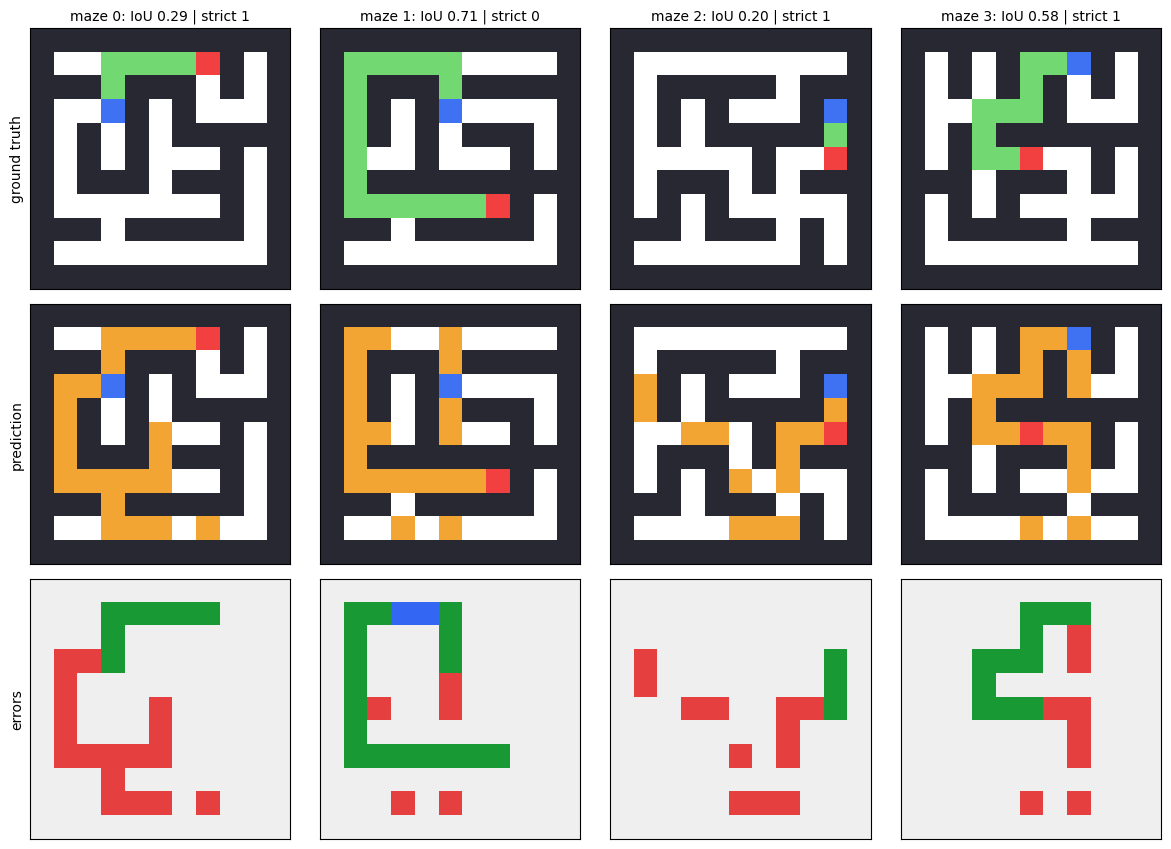

error map legend: dark green = hit | red = false positive | blue = missed cell | grey = correct negative


In [12]:
# ======================= 6. Held-out results + running example =======================
test_metrics = eval_dataset(rcnn, "test", T=8)
print("RecurrentCNN, held-out test split:")
print({k: round(v, 3) for k, v in test_metrics.items()})


def overlay(wall, start, goal, mask=None, mask_color=(0.45, 0.85, 0.45)):
    img = np.ones(wall.shape + (3,))
    img[wall == 1] = (0.16, 0.16, 0.20)
    if mask is not None:
        img[mask] = mask_color
    img[start] = (0.95, 0.25, 0.25)
    img[goal] = (0.25, 0.45, 0.95)
    return np.clip(img, 0, 1)


def show_running_example(model, split, T=8, n=4):
    x, y, walls, starts, goals, sols = data[split]
    fig, axes = plt.subplots(3, n, figsize=(3 * n, 8.6))
    for k in range(n):
        with torch.no_grad():
            prob = torch.sigmoid(model(x[k].unsqueeze(0), T=T))[0].numpy()
        pred = prob >= 0.5
        m = evaluate_mask(pred, walls[k], starts[k], goals[k], y[k])
        gt = y[k].numpy() > 0.5
        axes[0, k].imshow(overlay(walls[k], starts[k], goals[k], gt))
        axes[1, k].imshow(overlay(walls[k], starts[k], goals[k], pred,
                                  mask_color=(0.95, 0.65, 0.2)))
        err = np.full(gt.shape + (3,), 0.94)
        err[gt] = (0.45, 0.8, 0.5)
        err[pred & gt] = (0.1, 0.6, 0.2)
        err[pred & ~gt] = (0.9, 0.25, 0.25)
        err[gt & ~pred] = (0.2, 0.4, 0.95)
        axes[2, k].imshow(err)
        for row in range(3):
            axes[row, k].set_xticks([]); axes[row, k].set_yticks([])
        axes[0, k].set_title("maze %d: IoU %.2f | strict %d" % (k, m["iou"], m["strict"]),
                             fontsize=10)
    axes[0, 0].set_ylabel("ground truth")
    axes[1, 0].set_ylabel("prediction")
    axes[2, 0].set_ylabel("errors")
    plt.tight_layout()
    plt.show()
    print("error map legend: dark green = hit | red = false positive | "
          "blue = missed cell | grey = correct negative")


show_running_example(rcnn, "test")


## 7) P1: non-recurrent CNN control

A **plain feed-forward CNN**: no state, no loop. Depth 6 of stacked 3x3
convolutions gives a receptive field that covers the entire 11x11 ASCII grid,
at a comparable parameter budget (~12k vs ~10k). Purpose: separate
*"looping helps"* from *"depth alone helps"*.


In [13]:
# ======================= 7. P1: plain CNN control =======================
class PlainCNN(nn.Module):
    # depth-6 stack -> receptive field 11x11 (the whole grid); no loop
    def __init__(self, in_ch=3, hid=18, depth=6):
        super().__init__()
        layers = [nn.Conv2d(in_ch, hid, 3, padding=1), nn.GELU()]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(hid, hid, 3, padding=1), nn.GELU()]
        layers += [nn.Conv2d(hid, 1, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x, T=1):        # T accepted and ignored (no loop)
        return self.net(x).squeeze(1)


plain = PlainCNN().to(DEVICE)
print("PlainCNN params:", sum(p.numel() for p in plain.parameters()),
      "| RecurrentCNN params:", sum(p.numel() for p in rcnn.parameters()))
opt2 = torch.optim.Adam(plain.parameters(), lr=1e-3)
for ep in range(HYPERPARAMS["epochs"]):
    t0 = time.time()
    train_loss = run_epoch(plain, train_loader, T=1, optimizer=opt2)
    val_m = eval_dataset(plain, "val", T=1)
    print("epoch %d | train BCE %.4f | val IoU %.3f strict %.3f exact %.3f | %.1fs"
          % (ep, train_loss, val_m["iou"], val_m["strict"], val_m["exact"],
             time.time() - t0))
torch.save(plain.state_dict(), str(RESULTS / "plain_cnn_hf_week1.pt"))
print("checkpoint saved:", RESULTS / "plain_cnn_hf_week1.pt")


PlainCNN params: 12259 | RecurrentCNN params: 9989


/tmp/ipykernel_1337/1688800806.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  inter = int(np.logical_and(pred, gt).sum())
/tmp/ipykernel_1337/1688800806.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  union = int(np.logical_or(pred, gt).sum())


epoch 0 | train BCE 0.9359 | val IoU 0.241 strict 0.009 exact 0.000 | 3.4s
epoch 1 | train BCE 0.5590 | val IoU 0.378 strict 0.627 exact 0.000 | 3.8s
epoch 2 | train BCE 0.4548 | val IoU 0.384 strict 0.799 exact 0.000 | 4.1s
epoch 3 | train BCE 0.4040 | val IoU 0.450 strict 0.675 exact 0.001 | 3.2s
epoch 4 | train BCE 0.3784 | val IoU 0.447 strict 0.822 exact 0.002 | 3.3s
epoch 5 | train BCE 0.3595 | val IoU 0.488 strict 0.677 exact 0.001 | 4.2s
checkpoint saved: /content/week1_results/plain_cnn_hf_week1.pt


/tmp/ipykernel_1337/1688800806.py:30: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  inter = int(np.logical_and(pred, gt).sum())
/tmp/ipykernel_1337/1688800806.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  union = int(np.logical_or(pred, gt).sum())


model                        params      IoU   strict    exact  wall-hits  has-route
------------------------------------------------------------------------------------
RecurrentCNN (loop, T=8)       9989    0.548    0.799    0.007       0.03      0.820
PlainCNN (no loop)            12259    0.483    0.695    0.000       0.00      0.697


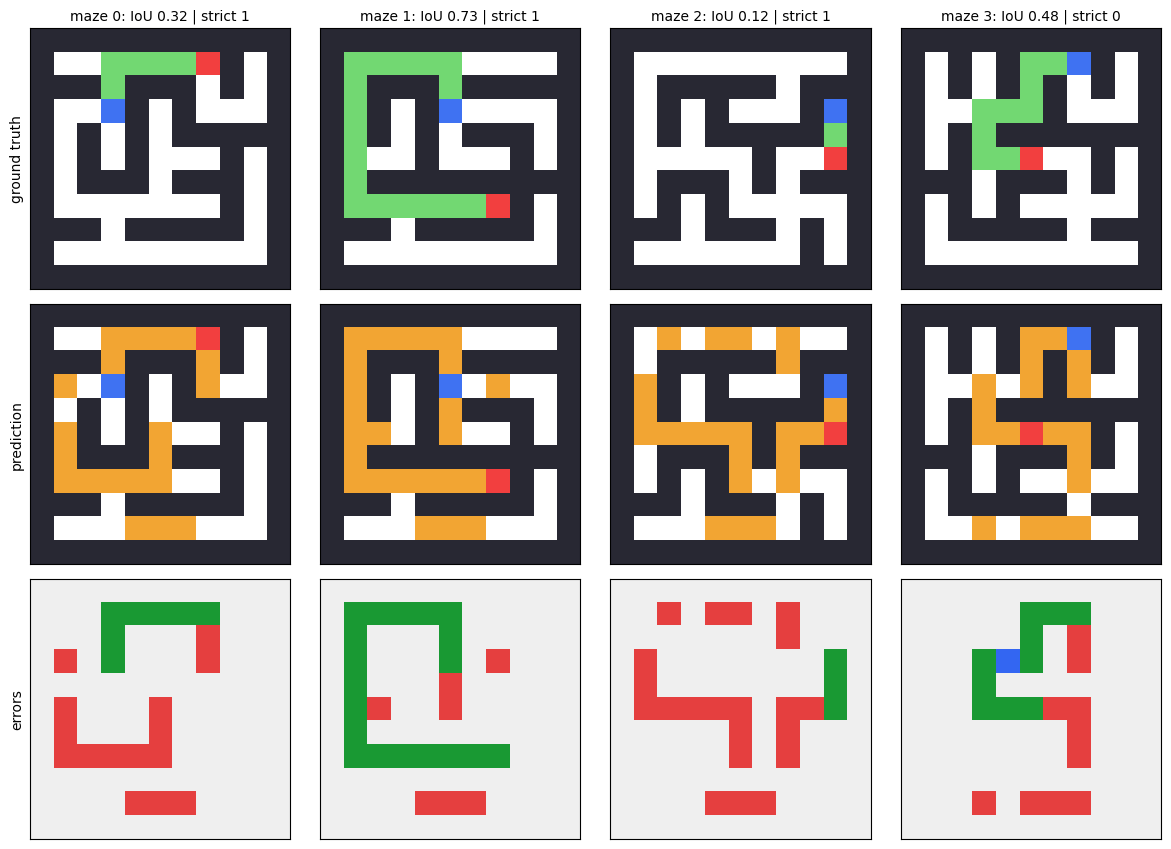

error map legend: dark green = hit | red = false positive | blue = missed cell | grey = correct negative


In [14]:
# ======================= 8. Model comparison table (held-out test) =======================
rows = []
for name, model, T in [("RecurrentCNN (loop, T=8)", rcnn, 8),
                      ("PlainCNN (no loop)", plain, 1)]:
    m = eval_dataset(model, "test", T=T)
    rows.append((name, sum(p.numel() for p in model.parameters()),
                 m["iou"], m["strict"], m["exact"], m["wall_hits"], m["has_route"]))

hdr = ("%-26s %8s %8s %8s %8s %10s %10s" %
       ("model", "params", "IoU", "strict", "exact", "wall-hits", "has-route"))
print(hdr)
print("-" * len(hdr))
for r in rows:
    print("%-26s %8d %8.3f %8.3f %8.3f %10.2f %10.3f" % r)

show_running_example(plain, "test", T=1)


## 9) Week-1 conclusions and limitations

**Delivered:** a documented pre-labeled dataset (Section 1), a search-free
data adapter from ASCII + provided solutions (Sections 2-3), verified samples,
a strict evaluation suite (Section 4), a trained RecurrentCNN baseline and a
plain-CNN control (Sections 5-8), with hyperparameters, comparison table,
running examples and error maps.

**Documented first hyperparameter set** (Section 5): Adam lr 1e-3, batch 32,
BCEWithLogits with pos_weight, threshold 0.5, T=8 (looped model only), 6 epochs.

**Identified limitations (input for Week 2):**

- labels here are **single-path** (Wilson perfect mazes) - simpler than the
  Milestone-1 union-of-ties labels; results are not comparable across the two
  label conventions without re-baselining;
- Week 1 uses only the easy grid_size=5 level (ASCII 11x11); the 7 and 9
  curriculum levels are the natural difficulty axis for Week-2/3 experiments;
- prediction evaluation uses a search (small BFS, Section 4) - labels never do;
  routing scores must always be shown next to IoU/exact-match (an all-free
  prediction "solves" routing);
- wall-blind messages: a 3x3 convolution sees through walls; wall-aware
  updates are the first Week-2 architecture investigation;
- T fixed at 8; frozen-weights T-sweeps are a Week-2/3 experiment;
- single seed; multi-seed replication belongs to the Week-3 protocol.

